# Orbit Wars — RL Observation & Set Transformer Policy

Bu defter, repo'da yeni eklenen iki modülü uçtan uca açıklar:

- **`obs_builder.py`** — Ham env observation'ını sabit şekilli numpy tensörlerine çeviren feature pipeline.
- **`model.py`** — Set Transformer tabanlı policy/value ağı.

## Neden bu mimari?

Orbit Wars'ın yapısı klasik RL ortamlarından farklı:

| Özellik | Tasarıma etkisi |
| --- | --- |
| Değişken sayıda gezegen (10–25) | Sabit boyutlu MLP ❌ → set/graph encoder ✅ |
| Değişken sayıda fleet (0..N) | Padding + mask gerek |
| Permutation invariance (gezegen sırası anlamsız) | Self-attention veya GNN |
| Aksiyon = `[from_id, angle, ships]` | Per-planet pointer head |
| Geometrik mantık kritik (mesafe, ETA) | Edge feature → attention bias |

**Kararımız**: Set Transformer + edge bias + masked pointer policy. PyG/DGL bağımlılığı yok; sadece `torch`.

In [1]:
import os, sys
REPO = os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..'))
sys.path.insert(0, REPO)
print('Repo root:', REPO)

Repo root: /home/doruk/Documents/Kaggle/Orbit_Wars


In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
from kaggle_environments import make

from feature_extraction import parse_planets, parse_fleets, SUN_X, SUN_Y, SUN_RADIUS
from obs_builder import (
    build_observation, decode_action,
    PLANET_FEATURE_DIM, FLEET_FEATURE_DIM, GLOBAL_FEATURE_DIM, EDGE_FEATURE_DIM,
)
from model import OrbitWarsPolicy, pack_observations
import torch

[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO: Successfully loaded OpenSpiel environments: 16.


[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_backgammon


[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_checkers


[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_chess


[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_connect_four


[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_gin_rummy


... (9 outputs left out)

[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_repeated_poker


[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_python_repeated_pokerkit


[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO: OpenSpiel games skipped: 1.


[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    snake


## 1. Bir oyun başlat ve raw observation al

In [3]:
env = make('orbit_wars', debug=False)
env.reset(2)
# `env.reset` allocates the env but doesn't generate the world; the first
# `env.step` populates planets, comets, and angular_velocity.
env.step([[], []])

obs0 = env.state[0].observation  # player 0 perspective
omega = obs0.get('angular_velocity', 0.0)
print(f'#planets = {len(obs0["planets"])}, #fleets = {len(obs0["fleets"])}, omega = {omega:.4f}')
print('Sample planet row:', obs0['planets'][0])
print('Observation keys:', list(obs0.keys()))

#planets = 28, #fleets = 0, omega = 0.0364
Sample planet row: [0, -1, 57.10396153900948, 97.71176481026066, 2.09861228866811, 13, 3]
Observation keys: ['remainingOverageTime', 'step', 'planets', 'fleets', 'player', 'angular_velocity', 'initial_planets', 'next_fleet_id', 'comets', 'comet_planet_ids']


Ham observation `dict`:

- `planets`: `[id, owner, x, y, radius, ships, production]` listesi
- `fleets`: `[id, owner, x, y, angle, from_planet_id, ships]` listesi (havadaki filolar)
- `initial_planets`: oyun başındaki gezegen konumları (rotating tipini belirlemek için)
- `comet_planet_ids`, `comets`: kuyruklu yıldız bilgileri
- `angular_velocity`: rotating gezegenlerin açısal hızı (sabit, oyuna özel)

Bu yapıyı doğrudan ağa veremeyiz: değişken uzunluk, karışık tipler, ölçeksiz değerler.

## 2. `build_observation` ile feature pipeline

Tek çağrıda raw obs → padded numpy tensörleri.

In [4]:
o = build_observation(obs0, player=0, angular_velocity=omega, turn=0)
print(f'planet_feats : {o.planet_feats.shape}  ({PLANET_FEATURE_DIM} feats)')
print(f'planet_mask  : {o.planet_mask.shape}  -> real planets = {int(o.planet_mask.sum())}')
print(f'source_mask  : {o.source_mask.shape}  -> launchable   = {int(o.source_mask.sum())}')
print(f'fleet_feats  : {o.fleet_feats.shape}  ({FLEET_FEATURE_DIM} feats)')
print(f'fleet_mask   : {o.fleet_mask.shape}   -> real fleets  = {int(o.fleet_mask.sum())}')
print(f'global_feats : {o.global_feats.shape}  ({GLOBAL_FEATURE_DIM} feats)')
print(f'edge_bias    : {o.edge_bias.shape}  -> T = P_max + F_max + 1 = {o.edge_bias.shape[0]}')
print(f'meta         : {o.meta}')

planet_feats : (48, 15)  (15 feats)
planet_mask  : (48,)  -> real planets = 28
source_mask  : (48,)  -> launchable   = 1
fleet_feats  : (64, 11)  (11 feats)
fleet_mask   : (64,)   -> real fleets  = 0
global_feats : (12,)  (12 feats)
edge_bias    : (113, 113, 5)  -> T = P_max + F_max + 1 = 113
meta         : {'n_planets': 28, 'n_fleets': 0, 'incoming_self': 0, 'incoming_other': 0, 'p_max': 48, 'f_max': 64}


### 2.1 Planet feature'ları (15-d)

| idx | feature | açıklama |
| --- | --- | --- |
| 0–2 | `is_self, is_enemy, is_neutral` | sahip one-hot |
| 3 | `ships / 100` | gemi sayısı normalize |
| 4 | `production / 5` | üretim normalize |
| 5 | `radius / 5` | gezegen yarıçapı (üretimi etkiler!) |
| 6 | `r_sun / 50` | güneşe uzaklık |
| 7,8 | `cos(theta), sin(theta)` | yörünge açısı (circular) |
| 9–11 | `is_static, is_rotating, is_comet` | tip one-hot |
| 12 | `omega * dt` | dönüş hızı (sadece rotating için) |
| 13 | `(ships+1) / 100` | ele geçirmek için min gerekli (kabaca) |
| 14 | `log(ships+1) / log(1000)` | logaritmik gemi (büyük orduların hız etkisi) |

Polar koordinatlar (`r_sun`, `cos/sin θ`) ham `(x, y)` yerine tercih edildi: Orbit Wars'ın simetrisi rotational, polar'da öğrenmek daha kolay.

In [5]:
import pandas as pd
cols = ['is_self','is_enemy','is_neutral','ships/100','prod/5','radius/5',
        'r_sun/50','cos(theta)','sin(theta)','is_static','is_rotating',
        'is_comet','omega*dt','ships_to_cap','log_ships']
n = int(o.planet_mask.sum())
df = pd.DataFrame(o.planet_feats[:n], columns=cols)
df.insert(0, 'planet_id', o.planet_ids[:n])
df.round(3)

,planet_id,is_self,is_enemy,is_neutral,ships/100,prod/5,radius/5,r_sun/50,cos(theta),sin(theta),is_static,is_rotating,is_comet,omega*dt,ships_to_cap,log_ships
0,0,0.0,0.0,1.0,0.13,0.6,0.420,0.965,0.147,0.989,1.0,0.0,0.0,0.000,0.14,0.382
1,1,0.0,0.0,1.0,0.13,0.6,0.420,0.965,-0.147,0.989,1.0,0.0,0.0,0.000,0.14,0.382
2,2,0.0,0.0,1.0,0.13,0.6,0.420,0.965,0.147,-0.989,1.0,0.0,0.0,0.000,0.14,0.382
3,3,0.0,0.0,1.0,0.13,0.6,0.420,0.965,-0.147,-0.989,1.0,0.0,0.0,0.000,0.14,0.382
4,4,1.0,0.0,0.0,0.10,0.8,0.477,1.054,0.603,0.797,1.0,0.0,0.0,0.000,0.00,0.347
5,5,0.0,0.0,1.0,0.58,0.8,0.477,1.054,-0.603,0.797,1.0,0.0,0.0,0.000,0.59,0.590
6,6,0.0,0.0,1.0,0.58,0.8,0.477,1.054,0.603,-0.797,1.0,0.0,0.0,0.000,0.59,0.590
7,7,0.0,1.0,0.0,0.10,0.8,0.477,1.054,-0.603,-0.797,1.0,0.0,0.0,0.000,0.11,0.347
8,8,0.0,0.0,1.0,0.24,0.8,0.477,0.994,0.929,0.370,1.0,0.0,0.0,0.000,0.25,0.466
9,9,0.0,0.0,1.0,0.24,0.8,0.477,0.994,-0.929,0.370,1.0,0.0,0.0,0.000,0.25,0.466


### 2.2 Fleet feature'ları (11-d)

Filo halihazırda uçuyor; agent açısını değiştiremez ama hedefi tahmin ederek karşı hamle planlayabilir.

| idx | feature |
| --- | --- |
| 0–1 | `is_self, is_enemy` |
| 2 | `ships / 100` |
| 3 | `log_ships` |
| 4 | `speed / max_speed` |
| 5,6 | `cos(angle), sin(angle)` |
| 7,8 | `x/100 - 0.5, y/100 - 0.5` (kart koord, merkez 0) |
| 9 | `predicted_eta / 50` (`navigation.predict_fleet_target` ile) |
| 10 | `has_predicted_target` |

ETA'yı hesaplayan deterministik tahmin fonksiyonumuz `navigation.predict_fleet_target` — observation'a hazır prior olarak giriyor, agent öğrenmek zorunda değil.

In [6]:
if o.fleet_mask.any():
    fcols = ['is_self','is_enemy','ships/100','log_ships','speed/max',
             'cos(a)','sin(a)','x_c','y_c','eta/50','has_pred']
    nf = int(o.fleet_mask.sum())
    fdf = pd.DataFrame(o.fleet_feats[:nf], columns=fcols)
    fdf.insert(0, 'fleet_id', o.fleet_ids[:nf])
    print(fdf.round(3))
else:
    print('Henüz havada filo yok — env\'i birkaç adım ilerletip tekrar bakabiliriz.')

Henüz havada filo yok — env'i birkaç adım ilerletip tekrar bakabiliriz.


### 2.3 Global feature'lar (12-d)

Bütün state'in özet istatistiği. Transformer içinde **CLS-style global token** olarak yer alır.

In [7]:
gcols = ['turn/200','omega','my_planets/25','enemy_planets/25','neutral/25',
        'my_ships/1000','enemy_ships/1000','my_prod/50','enemy_prod/50',
        'fleets/25','incoming_enemy/500','incoming_friendly/500']
for name, val in zip(gcols, o.global_feats):
    print(f'  {name:<22s} = {val:+.3f}')

  turn/200               = +0.000
  omega                  = +0.036
  my_planets/25          = +0.040
  enemy_planets/25       = +0.040
  neutral/25             = +1.040
  my_ships/1000          = +0.010
  enemy_ships/1000       = +0.010
  my_prod/50             = +0.080
  enemy_prod/50          = +0.080
  fleets/25              = +0.000
  incoming_enemy/500     = +0.000
  incoming_friendly/500  = +0.000


### 2.4 Edge bias matrisi (T × T × 5)

Token sırası: `[planet_0, ..., planet_{P-1}, fleet_0, ..., fleet_{F-1}, GLOBAL]`. Her çift için 5 feature:

- `dist / 100` — Öklid mesafesi (normalize)
- `dx / 100` — işaretli x farkı (yön)
- `dy / 100` — işaretli y farkı (yön)
- `sin(Δφ)` — güneş etrafındaki açı farkının sinüsü
- `cos(Δφ)` — güneş etrafındaki açı farkının kosinüsü

Son iki kanal, her token'ın güneşe göre polar açısı `φ = atan2(y − sun_y, x − sun_x)` kullanılarak hesaplanır. İki gezegen **aynı** `angular_velocity` ile döndüğü için aralarındaki `Δφ` zamanla değişmez — model bu sayede board rotasyonundan bağımsız, kalıcı bir orbital ilişki sinyali alır. `(dx, dy)` her turn döndüğü için anlık geometriyi, `(sin Δφ, cos Δφ)` ise zamandan bağımsız orbital ilişkiyi taşır.

Bu matris transformer'ın attention skorlarına **per-head additive bias** olarak eklenir; model, mesafeyi ve orbital yapıyı sıfırdan öğrenmek zorunda kalmaz.

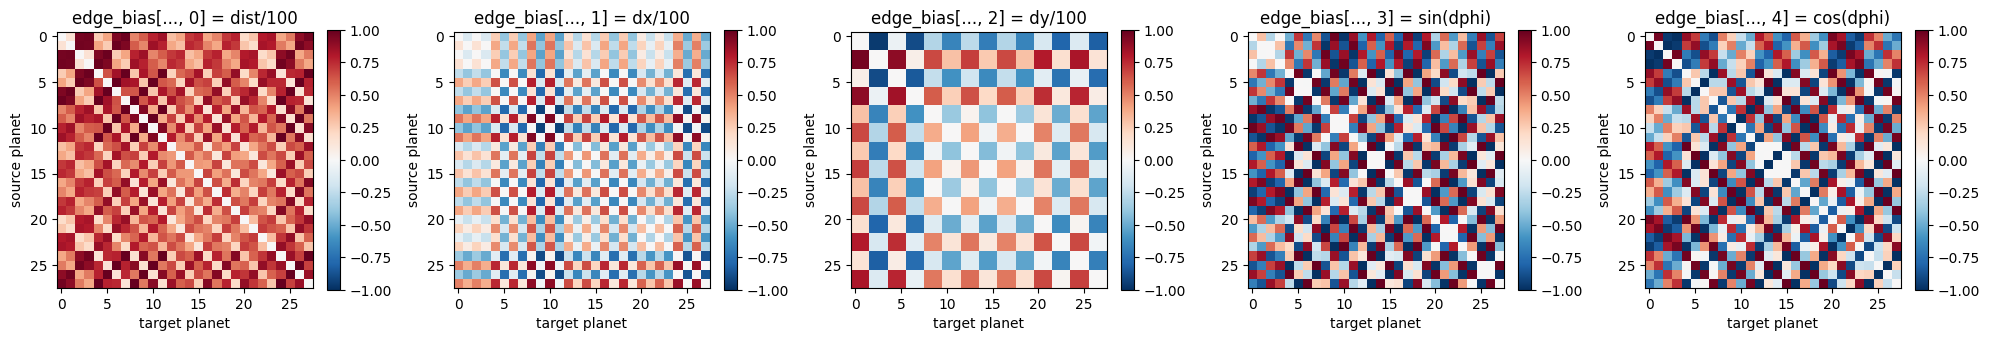

In [8]:
n = int(o.planet_mask.sum())
channel_names = ['dist/100', 'dx/100', 'dy/100', 'sin(dphi)', 'cos(dphi)']
fig, ax = plt.subplots(1, 5, figsize=(20, 4))
for idx, name in enumerate(channel_names):
    im = ax[idx].imshow(o.edge_bias[:n, :n, idx], cmap='RdBu_r', vmin=-1, vmax=1)
    ax[idx].set_title(f'edge_bias[..., {idx}] = {name}')
    ax[idx].set_xlabel('target planet'); ax[idx].set_ylabel('source planet')
    plt.colorbar(im, ax=ax[idx], fraction=0.046)
plt.tight_layout(); plt.show()

### 2.5 Maskeleme semantiği

Üç ayrı mask:

- **`planet_mask`**: gerçek gezegen mi, yoksa padding mi? Transformer attention bunları görmez.
- **`fleet_mask`**: aynısı filo için.
- **`source_mask`**: yalnızca **kendi gezegenlerimiz + yeterli gemisi olanlar** kaynak olabilir. Policy'nin `src` head'inde bu mask uygulanıyor → yasadışı kaynaklara olasılık sızmıyor.

In [9]:
n = int(o.planet_mask.sum())
owners = o.planet_feats[:n, :3].argmax(axis=1)  # 0=self, 1=enemy, 2=neutral
owner_label = {0:'self', 1:'enemy', 2:'neutral'}
print(f'{"slot":<5}{"id":<5}{"owner":<10}{"ships":<8}{"src_mask":<10}')
for i in range(n):
    ships = o.planet_feats[i, 3] * 100
    print(f'{i:<5d}{o.planet_ids[i]:<5d}{owner_label[owners[i]]:<10s}'
          f'{int(ships):<8d}{str(bool(o.source_mask[i])):<10s}')

slot id   owner     ships   src_mask  
0    0    neutral   13      False     
1    1    neutral   13      False     
2    2    neutral   13      False     
3    3    neutral   13      False     
4    4    self      10      True      
5    5    neutral   58      False     
6    6    neutral   58      False     
7    7    enemy     10      False     
8    8    neutral   24      False     
9    9    neutral   24      False     
10   10   neutral   24      False     
11   11   neutral   24      False     
12   12   neutral   13      False     
13   13   neutral   13      False     
14   14   neutral   13      False     
15   15   neutral   13      False     
16   16   neutral   24      False     
17   17   neutral   24      False     
18   18   neutral   24      False     
19   19   neutral   24      False     
20   20   neutral   19      False     
21   21   neutral   19      False     
22   22   neutral   19      False     
23   23   neutral   19      False     
24   24   neutral   6    

## 3. Set Transformer policy (`OrbitWarsPolicy`)

### 3.1 Token akışı

```
         planet feats (P, 15)         fleet feats (F, 11)        global feats (12,)
                │                            │                         │
         planet_proj                  fleet_proj               global_proj  (her biri Linear → d_model)
                │                            │                         │
                └────── concat ──────────────┴────── concat ───────────┘
                                       (B, T, d_model)
                                              │
                                  + type_embed (planet/fleet/global)
                                              │
                              ┌──── n_layers × TransformerBlock ────┐
                              │  (BiasedMHA: edge_bias → +attn)     │
                              │  (FFN: d → 4d → d)                  │
                              └─────────────────────────────────────┘
                                              │
                                   LayerNorm → tokens (B, T, d)
                                              │
                  ┌───────────────┬───────────┴────────┬──────────────────┐
          src_head        tgt_query/tgt_key       ship_head        value_head
      (B, P) + NO-OP     (B, P, P) pointer       (B, P, k)         (B,)
```

### 3.2 Aksiyon faktorizasyonu

```
src_slot ~ Cat(src_logits)            # P+1 (son slot = NO-OP)
tgt_slot ~ Cat(tgt_logits[src_slot])  # self-target ve padded gezegenler maskeli
ship_bin ~ Cat(ship_logits[src_slot]) # 5 ayrık fraksiyon: 10/25/50/75/100%
```

Açıyı agent seçmiyor — `compute_launch(src, tgt, ships)` deterministik olarak hesaplıyor. Bu, action space'i çok küçültüyor (continuous angle yerine discrete pointer).

In [10]:
torch.manual_seed(0)
net = OrbitWarsPolicy(d_model=64, n_heads=4, n_layers=2)
n_params = sum(p.numel() for p in net.parameters())
print(f'Toplam parametre: {n_params:,}')
print(net)

Toplam parametre: 115,872
OrbitWarsPolicy(
  (planet_proj): Linear(in_features=15, out_features=64, bias=True)
  (fleet_proj): Linear(in_features=11, out_features=64, bias=True)
  (global_proj): Linear(in_features=12, out_features=64, bias=True)
  (type_embed): Embedding(3, 64)
  (edge_proj): Linear(in_features=5, out_features=4, bias=True)
  (blocks): ModuleList(
    (0-1): 2 x TransformerBlock(
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (attn): BiasedMultiHeadAttention(
        (qkv): Linear(in_features=64, out_features=192, bias=True)
        (out_proj): Linear(in_features=64, out_features=64, bias=True)
      )
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (ff): Sequential(
        (0): Linear(in_features=64, out_features=256, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=256, out_features=64, bias=True)
      )
    )
  )
  (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (sr

### 3.3 Forward pass

Birden fazla observation'ı `pack_observations` ile batch'leyebiliriz. Burada tek observation'ı 3'lü batch yapıp deniyoruz.

In [11]:
batch = pack_observations([o, o, o])
out = net(**batch)
print(f'src_logits  : {tuple(out.src_logits.shape)}   (B, P_max+1)')
print(f'tgt_logits  : {tuple(out.tgt_logits.shape)}  (B, P_max, P_max)')
print(f'ship_logits : {tuple(out.ship_logits.shape)}  (B, P_max, n_ship_bins)')
print(f'value       : {tuple(out.value.shape)}             (B,)')
print(f'tokens      : {tuple(out.tokens.shape)}  (B, T, d_model)')

src_logits  : (3, 49)   (B, P_max+1)
tgt_logits  : (3, 48, 48)  (B, P_max, P_max)
ship_logits : (3, 48, 5)  (B, P_max, n_ship_bins)
value       : (3,)             (B,)
tokens      : (3, 113, 64)  (B, T, d_model)


In [12]:
out

PolicyOutput(src_logits=tensor([[-3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38, -1.7429e-01,
         -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38,
         -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38,
         -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38,
         -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38,
         -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38,
         -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38,
         -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38,
         -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38,
         -3.4028e+38, -3.4028e+38, -3.4028e+38,  0.0000e+00],
        [-3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38, -1.7429e-01,
         -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38,
         -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38, -3.4028e+38,
         -3.4028e+38, -3.4

### 3.4 Maskelemenin çalıştığını doğrulayalım

Padded gezegenlere ve geçersiz kaynaklara olasılık akmamalı.

In [13]:
src_probs = torch.softmax(out.src_logits, dim=-1)[0]
tgt_probs = torch.softmax(out.tgt_logits, dim=-1)[0]
n = int(o.planet_mask.sum())
P = net.p_max

print(f'n_real_planets = {n} / P_max = {P}')
print(f'Toplam src_probs = {src_probs.sum().item():.4f}  (1.0 olmalı)')
if n < P:
    pad_src = src_probs[n:P].sum().item()
    print(f'Padded slot src kütlesi = {pad_src:.2e}')
print(f'NO-OP olasılığı            = {src_probs[P].item():.3f}')
invalid_own = src_probs[:n][~torch.from_numpy(o.source_mask[:n])].sum().item()
print(f'Geçersiz kaynak (own değil / boş) = {invalid_own:.2e}')

print()
diag = tgt_probs.diagonal(dim1=0, dim2=1)
print(f'Diyagonal (self-target) max prob: {diag.max().item():.2e}')
if n < P:
    pad_tgt = tgt_probs[:n, n:].max().item()
    print(f'Padded target max prob: {pad_tgt:.2e}')
else:
    print('(P_max dolu, padded target slot kalmadı.)')

n_real_planets = 28 / P_max = 48
Toplam src_probs = 1.0000  (1.0 olmalı)
Padded slot src kütlesi = 0.00e+00
NO-OP olasılığı            = 0.543
Geçersiz kaynak (own değil / boş) = 0.00e+00

Diyagonal (self-target) max prob: 0.00e+00
Padded target max prob: 0.00e+00


Beklediğimiz gibi: padded ve yasadışı slotlara sızıntı yok (~`1e-7` veya daha düşük; `-inf` masking sayesinde).

### 3.5 Aksiyon örnekleme

`net.act(out)` her batch elemanı için bir aksiyon sampling yapar.

In [14]:
torch.manual_seed(42)
action = net.act(out, deterministic=False)
for k, v in action.items():
    print(f'  {k:<10s} = {v.tolist()}')

  src        = [4, 48, 48]
  tgt        = [3, 16, 16]
  ship_bin   = [3, 1, 3]
  is_noop    = [False, True, True]
  log_prob   = [-5.138801097869873, -0.6097931265830994, -0.6097931265830994]


## 4. Uçtan uca: obs → policy → env aksiyon

Policy'nin önerdiği `(src_slot, tgt_slot, ship_bin)` üçlüsünü `decode_action` ile env formatına (`[from_id, angle, ships]`) çeviriyoruz. `compute_launch` yörüngeyi ve açıyı çözer; geçerli yörünge yoksa `None` döner (NO-OP).

In [15]:
planets = parse_planets(obs0)
src_slot = int(action['src'][0].item())
tgt_slot = int(action['tgt'][0].item())
ship_bin = int(action['ship_bin'][0].item())
is_noop = bool(action['is_noop'][0].item())
print(f'Policy seçimi: src_slot={src_slot}, tgt_slot={tgt_slot}, ship_bin={ship_bin}, noop={is_noop}')

env_action = decode_action(o, src_slot, tgt_slot, ship_bin,
                           planets=planets, angular_velocity=omega,
                           no_op=is_noop)
print(f'Env aksiyonu: {env_action}')
if env_action is not None:
    fid, angle, ships = env_action
    print(f'  -> from_planet={fid}, angle={math.degrees(angle):+.1f}°, ships={ships}')

Policy seçimi: src_slot=4, tgt_slot=3, ship_bin=3, noop=False
Env aksiyonu: None


### 4.1 Random policy ile bir tur oynat

Henüz eğitim yok, ağırlıklar random. Yine de pipeline'ın çalıştığını gözlemleyebiliriz.

In [16]:
def policy_action(env_obs, player, omega, net):
    obs = build_observation(env_obs, player=player, angular_velocity=omega)
    batch = pack_observations([obs])
    out = net(**batch)
    a = net.act(out, deterministic=False)
    src = int(a['src'][0]); tgt = int(a['tgt'][0]); bin_ = int(a['ship_bin'][0])
    is_noop = bool(a['is_noop'][0])
    planets = parse_planets(env_obs)
    decoded = decode_action(obs, src, tgt, bin_, planets=planets,
                            angular_velocity=omega, no_op=is_noop)
    return [decoded] if decoded is not None else []  # env aksiyon listesi bekler

# Fresh env, prime the world with one empty step.
env.reset(2)
env.step([[], []])

for step in range(5):
    obs0 = env.state[0].observation
    obs1 = env.state[1].observation
    om = obs0.get('angular_velocity', 0.0)
    a0 = policy_action(obs0, 0, om, net)
    a1 = policy_action(obs1, 1, om, net)
    env.step([a0, a1])
    print(f'step {step+1}: p0 launched {len(a0)} fleet(s), p1 launched {len(a1)} fleet(s)')

final_obs = env.state[0].observation
print(f'\nFinal: planets={len(final_obs["planets"])}, fleets in flight={len(final_obs["fleets"])}')

step 1: p0 launched 1 fleet(s), p1 launched 0 fleet(s)
step 2: p0 launched 0 fleet(s), p1 launched 0 fleet(s)
step 3: p0 launched 0 fleet(s), p1 launched 0 fleet(s)
step 4: p0 launched 0 fleet(s), p1 launched 0 fleet(s)
step 5: p0 launched 1 fleet(s), p1 launched 1 fleet(s)

Final: planets=32, fleets in flight=3


## 5. Özet ve sonraki adımlar

**Bu defterde gördüklerimiz:**

1. **`obs_builder.build_observation`** — raw env obs → padded numpy tensörler (`Observation` dataclass).
2. **15-d planet, 11-d fleet, 12-d global** feature setleri; geometrik prior'lar (polar koord, log_ships, ETA tahmini) hazır.
3. **Edge bias (T×T×5)** — transformer'a mesafe, yön (`dx, dy`) ve güneşe göre orbital açı farkı (`sin Δφ, cos Δφ`) prior olarak akıyor. Son iki kanal tüm gezegenler aynı `angular_velocity` ile döndüğü için zamanla değişmez bir orbital ilişki sinyali sağlar.
4. **Üç maske**: `planet_mask` (padding), `fleet_mask` (padding), `source_mask` (yasadışı kaynaklar). Hepsi softmax öncesi `-inf` ile uygulanıyor.
5. **`OrbitWarsPolicy`** — Set Transformer + masked pointer policy + value head; aksiyon `(src, tgt, ship_bin)` olarak faktorize, NO-OP ekstra slotta.
6. **`decode_action`** policy çıktısını env aksiyonuna çeviriyor; açıyı `compute_launch` deterministik buluyor.

**Sıradaki adımlar (TODO):**

- `train_ppo.py` — vectorized env wrapper + GAE + entropy bonus.
- Reward shaping: kazanma sinyali çok seyrek; `Δ(ships + prod·planets) − Δ(opponent_total)` per-step shaping önerimiz.
- Self-play opponent pool: baseline `nearest sniper` + son N checkpoint.
- Sanity-check rollout: NO-OP oranı, başarısız `compute_launch` oranı, action latency ölçümü.